# 04 GNN Evaluation: Message-Passing Ablation

This notebook compares an MLP, GraphSAGE on real transaction edges, and GraphSAGE on degree-preserving rewired edges. The design isolates the value of message passing and observed topology.

Run the notebook from top to bottom with a clean kernel. Core CSV files are exported for downstream analysis; tables and figures are also shown inline.

## Imports and dependencies

In [1]:
from IPython.display import display
import sys
import os

# See progress_summary.md Section 9 / node2vec_clustering.py Section 4.2 for
# why this sys.exec_prefix patch is needed on this machine before `import torch`.
if not sys.exec_prefix.endswith(os.sep):
    sys.exec_prefix += os.sep
if not sys.base_exec_prefix.endswith(os.sep):
    sys.base_exec_prefix += os.sep

from pathlib import Path

import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.nn import SAGEConv

from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import f1_score, balanced_accuracy_score
from scipy import stats

## 0. Setup -- P3: message-passing ablation

In [2]:
# the earlier GraphSAGE experiment (Sec 9) showed GraphSAGE-with-real-edges was
# statistically indistinguishable from a static graph_structural RF/XGBoost
# baseline given the SAME structural node features. That comparison could not
# tell apart two explanations: (a) message passing over this graph's topology
# genuinely adds nothing beyond the per-node structural features themselves,
# or (b) message passing does help, but this particular capacity/architecture/
# sample-size setup could not realise it. P3 isolates message passing itself
# (holding node features, architecture, splits, and training protocol fixed)
# by comparing three conditions:
#   A. MLP        -- SAME node features, NO edges (no message passing at all)
#   B. GraphSAGE   -- SAME node features, REAL sampled-graph edges
#   C. GraphSAGE   -- SAME node features, DEGREE-PRESERVING REWIRED edges
#                     (nx.double_edge_swap: destroys the real adjacency
#                     semantics -- which specific nodes are connected to which
#                     -- while holding the degree sequence exactly fixed, so
#                     any B-vs-C difference cannot be explained by a trivial
#                     degree-distribution artifact)
# All three share the identical 153-seed balanced subset, identical
# StratifiedKFold(n_splits=5, random_state=42) fold assignment (from
# balanced_subset_robustness.py), and identical model capacity (2 "layers",
# hidden_dim=16, dropout=0.6) -- only the message-passing structure differs.
# Each condition is run across N_SEEDS distinct training seeds (varying
# weight init / dropout masks, and for condition C also the specific rewired
# graph instance) rather than a single seed, per the repeated-CV lesson
# already documented in Sec 5.2/9.4/methodology. These repetitions quantify
# conditional algorithmic variation on one fixed address subset, fold scheme
# and graph snapshot; they are not independent data samples. Condition C also
# varies the rewired graph, so its seed variation combines optimisation and
# rewiring randomness.
#
# Primary comparisons are pre-registered here (not chosen post-hoc after
# seeing results): (1) GraphSAGE-real-edges minus MLP, (2) GraphSAGE-real-edges
# minus GraphSAGE-rewired-edges. Language used to report the outcome avoids
# "proves message passing has no value" -- the correct scope is "no stable
# benefit from the observed neighbourhood structure was detected under this
# architecture and sampled graph."

RANDOM_STATE = 42
N_SPLITS = 5
N_SEEDS = 5
TRAIN_SEEDS = [42, 43, 44, 45, 46]
LABEL_COL = "label"
LABEL_ORDER = ["CEX", "DeFi", "Malicious_MEV"]
HIDDEN_DIM = 16
DROPOUT = 0.6
WEIGHT_DECAY = 1e-3
LR = 0.01
MAX_EPOCHS = 300
PATIENCE = 20
VAL_FRACTION = 0.2

# Optional CLI args: edges_file balanced_subset_dir out_subdir.
_cwd = Path.cwd().resolve()
PROJECT_ROOT = next(
    (
        candidate
        for candidate in [_cwd, *_cwd.parents]
        if (candidate / "00_data_graph").exists()
        and (candidate / "04_supervised").exists()
    ),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Run this notebook from the dissertation workspace.")
EDGES_FILE = PROJECT_ROOT / "00_data_graph" / "data" / "main" / "raw_edges_reconstructed.csv"
BALANCED_DIR = PROJECT_ROOT / "06_robustness_audit" / "outputs" / "balanced_subset"
OUT_SUBDIR = PROJECT_ROOT / "04_supervised" / "03_gnn_evaluation" / "message_passing_and_baseline_results"

OUT_DIR = Path(OUT_SUBDIR)
OUT_DIR.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c3c2b7",
    "axes.labelcolor": "#0b0b0b", "text.color": "#0b0b0b", "xtick.color": "#52514e",
    "ytick.color": "#52514e", "grid.color": "#e1e0d9", "font.size": 10,
})


def clean_address(x):
    if pd.isna(x):
        return np.nan
    return str(x).strip().lower()

## 1. Build the full graph (identical construction to the earlier GraphSAGE experiment)

In [3]:
edges = pd.read_csv(EDGES_FILE)
edges["source"] = edges["source"].apply(clean_address)
edges["target"] = edges["target"].apply(clean_address)
edges = edges.dropna(subset=["source", "target"])

G_directed = nx.from_pandas_edgelist(edges, source="source", target="target", edge_attr=["tx_count"], create_using=nx.DiGraph())
G_undirected = G_directed.to_undirected()
for _, _, d in G_undirected.edges(data=True):
    d["weight"] = d.get("tx_count", 1)

print(f"Real graph: {G_undirected.number_of_nodes()} nodes, {G_undirected.number_of_edges()} edges")

Real graph: 8029 nodes, 46953 edges


## 2. Structural node features (identical to the earlier GraphSAGE experiment Sec 2)

In [4]:
in_degree = dict(G_directed.in_degree())
out_degree = dict(G_directed.out_degree())
pagerank_rank = pd.Series(nx.pagerank(G_directed)).rank(pct=True)
pagerank_weighted_rank = pd.Series(nx.pagerank(G_directed, weight="tx_count")).rank(pct=True)
clustering = nx.clustering(G_undirected)
wcc_size = {}
for component in nx.weakly_connected_components(G_directed):
    size = len(component)
    for node in component:
        wcc_size[node] = size

nodes = list(G_undirected.nodes())
struct_df = pd.DataFrame({
    "in_degree": pd.Series(in_degree), "out_degree": pd.Series(out_degree),
    "pagerank_rank": pagerank_rank, "pagerank_weighted_rank": pagerank_weighted_rank,
    "clustering_coeff": pd.Series(clustering), "wcc_size": pd.Series(wcc_size),
}).reindex(nodes).fillna(0.0)
struct_df["degree"] = struct_df["in_degree"] + struct_df["out_degree"]
struct_df["log_degree"] = np.log1p(struct_df["degree"])
struct_df["has_closed_triangle"] = (struct_df["clustering_coeff"] > 0).astype(float)
feature_cols = ["in_degree", "out_degree", "degree", "pagerank_rank", "pagerank_weighted_rank",
                "clustering_coeff", "has_closed_triangle", "wcc_size", "log_degree"]
struct_df = struct_df[feature_cols]

X_all = StandardScaler().fit_transform(struct_df.to_numpy(dtype=float))
x = torch.tensor(X_all, dtype=torch.float)
node_to_idx = {addr: i for i, addr in enumerate(nodes)}
print(f"Node feature matrix: {X_all.shape} (shared identically across all 3 conditions)")

Node feature matrix: (8029, 9) (shared identically across all 3 conditions)


## 3. Edge tensors for conditions B (real) and C (degree-preserving rewired)

In [5]:
edges_list_real = list(G_undirected.edges())


def edges_to_pyg_index(edges_list):
    src = [node_to_idx[u] for u, v in edges_list] + [node_to_idx[v] for u, v in edges_list]
    dst = [node_to_idx[v] for u, v in edges_list] + [node_to_idx[u] for u, v in edges_list]
    return torch.tensor([src, dst], dtype=torch.long)


edge_index_real = edges_to_pyg_index(edges_list_real)
# P3 isolates adjacency structure with unweighted undirected message passing;
# tx_count enters only through the weighted PageRank node feature.


def make_rewired_edge_index(seed):
    """Degree-preserving rewiring via repeated random edge swaps: destroys
    which-node-connects-to-which while holding the exact degree sequence."""
    G_rewired = G_undirected.copy()
    n_edges = G_rewired.number_of_edges()
    try:
        nx.double_edge_swap(G_rewired, nswap=n_edges * 5, max_tries=n_edges * 50, seed=seed)
    except nx.NetworkXAlgorithmError:
        pass  # graph too sparse in places to hit the full nswap target -- proceeds with whatever swaps succeeded
    assert sorted(dict(G_rewired.degree()).values()) == sorted(dict(G_undirected.degree()).values()), \
        "degree sequence not preserved by rewiring"
    return edges_to_pyg_index(list(G_rewired.edges()))

## 4. Load the SAME 153-seed balanced subset + SAME fold assignment

In [6]:
balanced = pd.read_csv(f"{BALANCED_DIR}/balanced_subset_seeds.csv")
assert balanced["address"].isin(node_to_idx).all()
balanced_idx = balanced["address"].map(node_to_idx).to_numpy()
label_encoder = LabelEncoder().fit(LABEL_ORDER)
y_bal = label_encoder.transform(balanced[LABEL_COL].to_numpy())

skf = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)
FOLD_SPLITS = list(skf.split(balanced_idx, y_bal))  # SAME splits reused across every condition x seed
print(f"Balanced subset: {len(balanced)} seeds, {N_SPLITS} folds (fixed across all conditions/seeds), {N_SEEDS} training seeds per condition")

Balanced subset: 153 seeds, 5 folds (fixed across all conditions/seeds), 5 training seeds per condition


## 5. Models: MLP (no message passing) vs SAGEConv (with message passing)

In [7]:
class SAGE(nn.Module):
    def __init__(self, in_dim, hidden_dim, out_dim, dropout):
        super().__init__()
        self.conv1 = SAGEConv(in_dim, hidden_dim)
        self.conv2 = SAGEConv(hidden_dim, out_dim)
        self.dropout = dropout

    def forward(self, x, edge_index):
        h = self.conv1(x, edge_index)
        h = F.relu(h)
        h = F.dropout(h, p=self.dropout, training=self.training)
        h = self.conv2(h, edge_index)
        return h


class MLP(nn.Module):
    """Same depth/width/dropout as SAGE, but no neighbourhood aggregation --
    each node is transformed independently of the graph structure."""
    def __init__(self, in_dim, hidden_dim, out_dim, dropout):
        super().__init__()
        self.lin1 = nn.Linear(in_dim, hidden_dim)
        self.lin2 = nn.Linear(hidden_dim, out_dim)
        self.dropout = dropout

    def forward(self, x, edge_index=None):
        h = self.lin1(x)
        h = F.relu(h)
        h = F.dropout(h, p=self.dropout, training=self.training)
        h = self.lin2(h)
        return h


def train_one_fold(model_ctor, edge_index, train_pos_idx, val_pos_idx, test_pos_idx, node_idx_array, y_array, train_seed):
    train_nodes = torch.tensor(node_idx_array[train_pos_idx], dtype=torch.long)
    val_nodes = torch.tensor(node_idx_array[val_pos_idx], dtype=torch.long)
    test_nodes = torch.tensor(node_idx_array[test_pos_idx], dtype=torch.long)
    y_train = torch.tensor(y_array[train_pos_idx], dtype=torch.long)
    y_val = torch.tensor(y_array[val_pos_idx], dtype=torch.long)
    y_test_np = y_array[test_pos_idx]

    torch.manual_seed(train_seed)
    model = model_ctor(in_dim=x.shape[1], hidden_dim=HIDDEN_DIM, out_dim=len(LABEL_ORDER), dropout=DROPOUT)
    optimizer = torch.optim.Adam(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)

    best_val_f1 = -1.0
    best_state = None
    epochs_since_improve = 0
    epoch = 0

    for epoch in range(MAX_EPOCHS):
        model.train()
        optimizer.zero_grad()
        out = model(x, edge_index)
        loss = F.cross_entropy(out[train_nodes], y_train)
        loss.backward()
        optimizer.step()

        model.eval()
        with torch.no_grad():
            out_eval = model(x, edge_index)
            val_pred = out_eval[val_nodes].argmax(dim=1).numpy()
            val_f1 = f1_score(y_val.numpy(), val_pred, average="macro", zero_division=0)

        if val_f1 > best_val_f1:
            best_val_f1 = val_f1
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
            epochs_since_improve = 0
        else:
            epochs_since_improve += 1
            if epochs_since_improve >= PATIENCE:
                break

    model.load_state_dict(best_state)
    model.eval()
    with torch.no_grad():
        out_final = model(x, edge_index)
        test_pred = out_final[test_nodes].argmax(dim=1).numpy()

    return {
        "macro_f1": f1_score(y_test_np, test_pred, average="macro", zero_division=0),
        "balanced_accuracy": balanced_accuracy_score(y_test_np, test_pred),
        "n_epochs_trained": epoch + 1,
    }

## 6. Run all 3 conditions x N_SEEDS x N_SPLITS

In [8]:
CONDITIONS = ["A_MLP_no_edges", "B_GraphSAGE_real_edges", "C_GraphSAGE_rewired_edges"]
rng_master = np.random.default_rng(RANDOM_STATE)
fold_rows = []

for train_seed in TRAIN_SEEDS:
    rewired_edge_index = make_rewired_edge_index(seed=train_seed)  # fresh rewiring instance per training seed
    for condition in CONDITIONS:
        if condition == "A_MLP_no_edges":
            model_ctor, ei = MLP, edge_index_real  # edge_index unused by MLP.forward but passed for interface symmetry
        elif condition == "B_GraphSAGE_real_edges":
            model_ctor, ei = SAGE, edge_index_real
        else:
            model_ctor, ei = SAGE, rewired_edge_index

        rng = np.random.default_rng(train_seed)
        for fold_i, (train_pos, test_pos) in enumerate(FOLD_SPLITS):
            train_pos = rng.permutation(train_pos)
            n_val = max(len(LABEL_ORDER), int(len(train_pos) * VAL_FRACTION))
            val_pos, fit_pos = train_pos[:n_val], train_pos[n_val:]

            result = train_one_fold(model_ctor, ei, fit_pos, val_pos, test_pos, balanced_idx, y_bal, train_seed)
            result.update({"condition": condition, "train_seed": train_seed, "fold": fold_i})
            fold_rows.append(result)
        print(f"[{condition}] train_seed={train_seed}: folds done, "
              f"mean macro_f1 so far = {np.mean([r['macro_f1'] for r in fold_rows if r['condition'] == condition and r['train_seed'] == train_seed]):.4f}")

fold_df = pd.DataFrame(fold_rows)[["condition", "train_seed", "fold", "macro_f1", "balanced_accuracy", "n_epochs_trained"]]
fold_df.to_csv(OUT_DIR / "p3_ablation_fold_scores.csv", index=False)
print(f"\nSaved {OUT_DIR / 'p3_ablation_fold_scores.csv'} ({len(fold_df)} rows = {len(CONDITIONS)} conditions x {N_SEEDS} seeds x {N_SPLITS} folds)")

[A_MLP_no_edges] train_seed=42: folds done, mean macro_f1 so far = 0.6955


[B_GraphSAGE_real_edges] train_seed=42: folds done, mean macro_f1 so far = 0.7421


[C_GraphSAGE_rewired_edges] train_seed=42: folds done, mean macro_f1 so far = 0.6391


[A_MLP_no_edges] train_seed=43: folds done, mean macro_f1 so far = 0.6616


[B_GraphSAGE_real_edges] train_seed=43: folds done, mean macro_f1 so far = 0.7413


[C_GraphSAGE_rewired_edges] train_seed=43: folds done, mean macro_f1 so far = 0.4485


... (5 outputs left out)

[C_GraphSAGE_rewired_edges] train_seed=45: folds done, mean macro_f1 so far = 0.6282


[A_MLP_no_edges] train_seed=46: folds done, mean macro_f1 so far = 0.7118


[B_GraphSAGE_real_edges] train_seed=46: folds done, mean macro_f1 so far = 0.7132


[C_GraphSAGE_rewired_edges] train_seed=46: folds done, mean macro_f1 so far = 0.5967

Saved E:\dissertation\04_supervised\03_gnn_evaluation\message_passing_and_baseline_results\p3_ablation_fold_scores.csv (75 rows = 3 conditions x 5 seeds x 5 folds)


## 7. Seed-level aggregation (mean macro-F1 across the 5 folds, per condition x seed) -- this is the unit of analysis for the paired comparisons, analogous to the repeat-level aggregation lesson in 02_repeated_cv.ipynb Section 5 / progress_ summary.md Sec 5.2 (fold-level rows within one seed/split share the same fixed fold assignment and are not independent observations).

In [9]:
seed_level = fold_df.groupby(["condition", "train_seed"])["macro_f1"].mean().reset_index()
seed_level_pivot = seed_level.pivot(index="train_seed", columns="condition", values="macro_f1")
# Displayed inline; external export omitted.
print(f"\n=== Seed-level mean macro-F1 (mean over {N_SPLITS} folds, per training seed) ===\n{seed_level_pivot.to_string()}")

summary_rows = []
for cond in CONDITIONS:
    vals = seed_level_pivot[cond].values
    summary_rows.append({"condition": cond, "n_seeds": len(vals), "macro_f1_mean": vals.mean(), "macro_f1_std": vals.std()})
summary_df = pd.DataFrame(summary_rows).round(4)
# Displayed inline; external export omitted.
print(f"\n=== Condition summary (aggregated across {N_SEEDS} training seeds) ===\n{summary_df.to_string(index=False)}")


=== Seed-level mean macro-F1 (mean over 5 folds, per training seed) ===
condition   A_MLP_no_edges  B_GraphSAGE_real_edges  C_GraphSAGE_rewired_edges
train_seed                                                                   
42                0.695490                0.742139                   0.639101
43                0.661645                0.741310                   0.448503
44                0.685883                0.744545                   0.560070
45                0.675905                0.658782                   0.628177
46                0.711767                0.713196                   0.596694

=== Condition summary (aggregated across 5 training seeds) ===
                condition  n_seeds  macro_f1_mean  macro_f1_std
           A_MLP_no_edges        5         0.6861        0.0170
   B_GraphSAGE_real_edges        5         0.7200        0.0327
C_GraphSAGE_rewired_edges        5         0.5745        0.0687


## 8. Pre-specified conditional comparisons across training-seed labels

In [10]:
primary_comparisons = [
    ("B_GraphSAGE_real_edges", "A_MLP_no_edges", "GraphSAGE(real edges) - MLP(no edges)"),
    ("B_GraphSAGE_real_edges", "C_GraphSAGE_rewired_edges", "GraphSAGE(real edges) - GraphSAGE(degree-preserving rewired edges)"),
]
comparison_rows = []
for cond_a, cond_b, label in primary_comparisons:
    a = seed_level_pivot[cond_a].values
    b = seed_level_pivot[cond_b].values
    diff = a - b
    n = len(diff)
    mean_diff = diff.mean()
    sem = diff.std(ddof=1) / np.sqrt(n) if n > 1 else np.nan
    if n > 1:
        ci_lo = mean_diff - stats.t.ppf(0.975, n - 1) * sem
        ci_hi = mean_diff + stats.t.ppf(0.975, n - 1) * sem
        t_stat, p_val = stats.ttest_rel(a, b)
    else:
        ci_lo = ci_hi = t_stat = p_val = np.nan
    comparison_rows.append({
        "comparison": label, "n_seeds": n, "mean_diff": mean_diff,
        "diff_95ci_lo": ci_lo, "diff_95ci_hi": ci_hi,
        "paired_t_stat": t_stat, "paired_p_value": p_val,
        "pct_seeds_a_better": (diff > 0).mean(),
    })
comparison_df = pd.DataFrame(comparison_rows).round(4)
comparison_df.to_csv(OUT_DIR / "p3_ablation_primary_comparisons.csv", index=False)
print(f"\n=== Pre-registered primary comparisons (paired across {N_SEEDS} training seeds) ===\n{comparison_df.to_string(index=False)}")
print(f"Saved {OUT_DIR / 'p3_ablation_primary_comparisons.csv'}")


=== Pre-registered primary comparisons (paired across 5 training seeds) ===
                                                        comparison  n_seeds  mean_diff  diff_95ci_lo  diff_95ci_hi  paired_t_stat  paired_p_value  pct_seeds_a_better
                             GraphSAGE(real edges) - MLP(no edges)        5     0.0339       -0.0163        0.0840         1.8740          0.1342                 0.8
GraphSAGE(real edges) - GraphSAGE(degree-preserving rewired edges)        5     0.1455        0.0228        0.2682         3.2919          0.0302                 1.0
Saved E:\dissertation\04_supervised\03_gnn_evaluation\message_passing_and_baseline_results\p3_ablation_primary_comparisons.csv


## 9. Plot

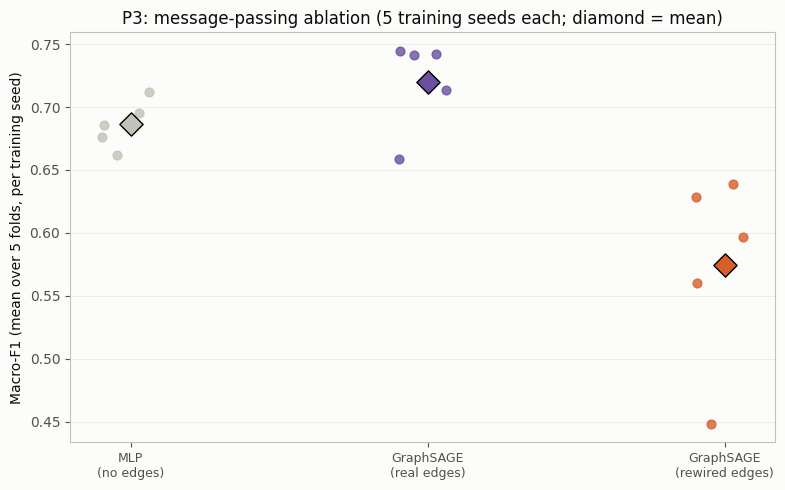


=== P3 message-passing ablation complete ===


In [11]:
fig, ax = plt.subplots(figsize=(8, 5))
colors = {"A_MLP_no_edges": "#c3c2b7", "B_GraphSAGE_real_edges": "#6b4fa0", "C_GraphSAGE_rewired_edges": "#d65f2a"}
labels_plot = ["MLP\n(no edges)", "GraphSAGE\n(real edges)", "GraphSAGE\n(rewired edges)"]
for i, cond in enumerate(CONDITIONS):
    vals = seed_level_pivot[cond].values
    xs = np.full(len(vals), i) + np.random.default_rng(0).uniform(-0.1, 0.1, size=len(vals))
    ax.scatter(xs, vals, color=colors[cond], s=40, alpha=0.8)
    ax.scatter([i], [vals.mean()], color=colors[cond], s=140, marker="D", edgecolor="black", linewidth=1, zorder=5)
ax.set_xticks(range(len(CONDITIONS)))
ax.set_xticklabels(labels_plot, fontsize=9)
ax.set_ylabel(f"Macro-F1 (mean over {N_SPLITS} folds, per training seed)")
ax.set_title(f"P3: message-passing ablation ({N_SEEDS} training seeds each; diamond = mean)")
ax.grid(axis="y", linewidth=0.6, alpha=0.6)
ax.set_axisbelow(True)
fig.tight_layout()
display(fig)
plt.close(fig)

print("\n=== P3 message-passing ablation complete ===")

## Key result tables

In [12]:
display(summary_df)
display(seed_level_pivot)
display(comparison_df)

,condition,n_seeds,macro_f1_mean,macro_f1_std
0,A_MLP_no_edges,5,0.6861,0.0170
1,B_GraphSAGE_real_edges,5,0.7200,0.0327
2,C_GraphSAGE_rewired_edges,5,0.5745,0.0687


condition,A_MLP_no_edges,B_GraphSAGE_real_edges,C_GraphSAGE_rewired_edges
train_seed,,,
42,0.695490,0.742139,0.639101
43,0.661645,0.741310,0.448503
44,0.685883,0.744545,0.560070
45,0.675905,0.658782,0.628177
46,0.711767,0.713196,0.596694


,comparison,n_seeds,mean_diff,diff_95ci_lo,diff_95ci_hi,paired_t_stat,paired_p_value,pct_seeds_a_better
0,GraphSAGE(real edges) - MLP(no edges),5,0.0339,-0.0163,0.0840,1.8740,0.1342,0.8
1,GraphSAGE(real edges) - GraphSAGE(degree-prese...,5,0.1455,0.0228,0.2682,3.2919,0.0302,1.0


## Interpretation

The primary comparisons separate the contribution of real graph topology from node features and degree sequence alone.